# 012 - MLP com perda ponderada

## Objetivo

Comparar `CrossEntropyLoss` sem pesos com a mesma perda ponderada pelo inverso da frequência de cada classe. Mantemos a arquitetura 64 → 32 com ReLU, 16 logits, Adam (`learning_rate=0.001`, `weight_decay=0`), `batch_size=128`, semente 42 e até 100 épocas, como no 010. Só varia a ponderação da perda.

Usamos exatamente a divisão estratificada fixa 80/20 e a validação interna estratificada do 010. Os pesos da comparação são calculados apenas em `y_inner_train`. Cada versão escolhe a primeira época com melhor Macro F1 interna; a versão com maior Macro F1 interna é reajustada numa rede nova nos 80% completos e avaliada uma vez nos 20% fixos. Se vencer a versão ponderada, os pesos são recalculados nesses 80%. Este notebook não gera CSV.

## Ambiente, dados e partições

Reutilizamos a preparação comum, a divisão fixa (`test_size=0.2`, `random_state=42`) e a validação interna de 15% (`random_state=42`, estratificada) do 010. A validação fixa não participa no cálculo de pesos, escolha de época ou seleção da perda.

In [1]:
import sys
import matplotlib.pyplot as plt
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import torch
from sklearn.model_selection import train_test_split

candidate_roots = [Path.cwd(), *Path.cwd().resolve().parents]
repo_root = next(
    (p for p in candidate_roots if (p / 'notebooks').is_dir() and (p / 'src' / 'preparar_dados.py').is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError('Não foi possível localizar a raiz do projeto com notebooks/ e src/preparar_dados.py.')
sys.path.insert(0, str(repo_root))
from src.preparar_dados import build_preprocessor, make_stratified_split, preparar_dados

train_path = repo_root / 'notebooks' / 'dataset_train.csv'
test_path = repo_root / 'notebooks' / 'dataset_test_X.csv'
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError(f'CSV de treino/teste não encontrados em {repo_root / "notebooks"}')

print(f'Python: {sys.version}')
print(f'PyTorch: {torch.__version__}; scikit-learn: {sklearn.__version__}')
print(f'Dispositivo: CPU')
print(f'Raiz do projeto: {repo_root}')

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
prepared = preparar_dados(train_df, test_df)
X_train, X_val, y_train, y_val = make_stratified_split(
    prepared['X_train'], prepared['y_train'], test_size=0.2, random_state=42
)
assert len(X_train) == 8769 and len(X_val) == 2193
assert sorted(y_train.unique().tolist()) == list(range(16))
print(f'Treino da experiência: {X_train.shape}; validação fixa reservada: {X_val.shape}')

X_inner_train, X_inner_val, y_inner_train, y_inner_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train,
)
assert X_inner_train.columns.equals(X_inner_val.columns)
print(f'Treino interno: {X_inner_train.shape}; validação interna: {X_inner_val.shape}')

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 11:23:37) [Clang 14.0.6 ]
PyTorch: 2.15.0; scikit-learn: 1.6.1
Dispositivo: CPU
Raiz do projeto: /Users/eduardaferreira/daa-kaggle-2026-2027


Treino da experiência: (8769, 236); validação fixa reservada: (2193, 236)
Treino interno: (7453, 236); validação interna: (1316, 236)


## Pré-processamento e pesos internos

O pré-processador é ajustado apenas em `X_inner_train`; ambas as perdas usam exatamente as mesmas matrizes transformadas. A ponderação inversa é normalizada para média 1 (`N / (K × contagem_da_classe)`), calculada exclusivamente nos alvos do treino interno. A perda não ponderada usa `CrossEntropyLoss()` sem pesos.

In [2]:
import random
import time
from sklearn.metrics import f1_score

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 100
LEARNING_RATE = 0.001
HIDDEN_SIZES = (64, 32)
NUM_CLASSES = 16

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

def to_dense_float32(matrix):
    if hasattr(matrix, 'toarray'):
        matrix = matrix.toarray()
    return np.asarray(matrix, dtype=np.float32)

inner_preprocessor = build_preprocessor(
    X_inner_train,
    normalize_numeric=True,
)
X_inner_train_array = to_dense_float32(inner_preprocessor.transform(X_inner_train))
X_inner_val_array = to_dense_float32(inner_preprocessor.transform(X_inner_val))
y_inner_train_array = y_inner_train.to_numpy(dtype=np.int64)
y_inner_val_array = y_inner_val.to_numpy(dtype=np.int64)
input_size = X_inner_train_array.shape[1]
estimated_bytes = (X_inner_train_array.nbytes + X_inner_val_array.nbytes) / (1024 ** 2)
print(f'Características transformadas: {input_size}')
print(f'Memória aproximada das matrizes densas: {estimated_bytes:.1f} MiB')

class AgeRangeMLP(torch.nn.Module):
    def __init__(self, input_features):
        super().__init__()
        self.layers = torch.nn.Sequential(
            torch.nn.Linear(input_features, 64),
            torch.nn.ReLU(),
            torch.nn.Linear(64, 32),
            torch.nn.ReLU(),
            torch.nn.Linear(32, NUM_CLASSES),
        )

    def forward(self, features):
        return self.layers(features)

def make_mlp(input_features, seed=SEED):
    torch.manual_seed(seed)
    return AgeRangeMLP(input_features).to('cpu')

def macro_f1_from_logits(logits, targets):
    predictions = logits.argmax(dim=1).cpu().numpy()
    return f1_score(
        targets,
        predictions,
        labels=list(range(NUM_CLASSES)),
        average='macro',
        zero_division=0,
    )

def evaluate_loss_f1(model, features, targets, criterion):
    model.eval()
    with torch.no_grad():
        logits = model(torch.from_numpy(features))
        loss = criterion(logits, torch.from_numpy(targets))
        score = macro_f1_from_logits(logits, targets)
    return float(loss.item()), float(score)

def inverse_frequency_weights(targets):
    counts = np.bincount(targets, minlength=NUM_CLASSES)
    if np.any(counts == 0):
        raise ValueError(f'Classes ausentes no conjunto usado para calcular pesos: {np.flatnonzero(counts == 0).tolist()}')
    weights = len(targets) / (NUM_CLASSES * counts)
    return torch.tensor(weights, dtype=torch.float32)

print(make_mlp(input_size))
print(f'Pesos inversos calculados apenas no treino interno: {inverse_frequency_weights(y_inner_train_array).tolist()}')

Características transformadas: 2324
Memória aproximada das matrizes densas: 77.7 MiB
AgeRangeMLP(
  (layers): Sequential(
    (0): Linear(in_features=2324, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
)
Pesos inversos calculados apenas no treino interno: [3.3036346435546875, 3.9813034534454346, 1.7188652753829956, 1.8125, 1.5272541046142578, 1.0586647987365723, 0.7976241707801819, 0.7949018478393555, 0.757418692111969, 0.6760703921318054, 0.6451696753501892, 0.6588578224182129, 0.6850183606147766, 0.8332960605621338, 1.0538744926452637, 1.378143548965454]


## Comparação e escolha

As duas versões começam com os mesmos pesos iniciais e ordem determinística dos minibatches. Para cada época guardamos perdas e Macro F1 de treino interno e validação interna. Escolhemos a primeira época de Macro F1 interna máxima de cada versão; a versão selecionada é a de maior Macro F1 interna (empates favorecem a versão sem pesos).

,versao,best_epoch,train_macro_f1,validation_macro_f1,train_loss,validation_loss,training_seconds
0,pesos inversos,12,0.672711,0.474236,0.868240,1.307422,19.317696
1,sem pesos,18,0.736594,0.467805,0.716612,1.380989,19.632272


Versão selecionada pela Macro F1 interna: pesos inversos
Época selecionada: 12
Macro F1 interna selecionada: 0.4742


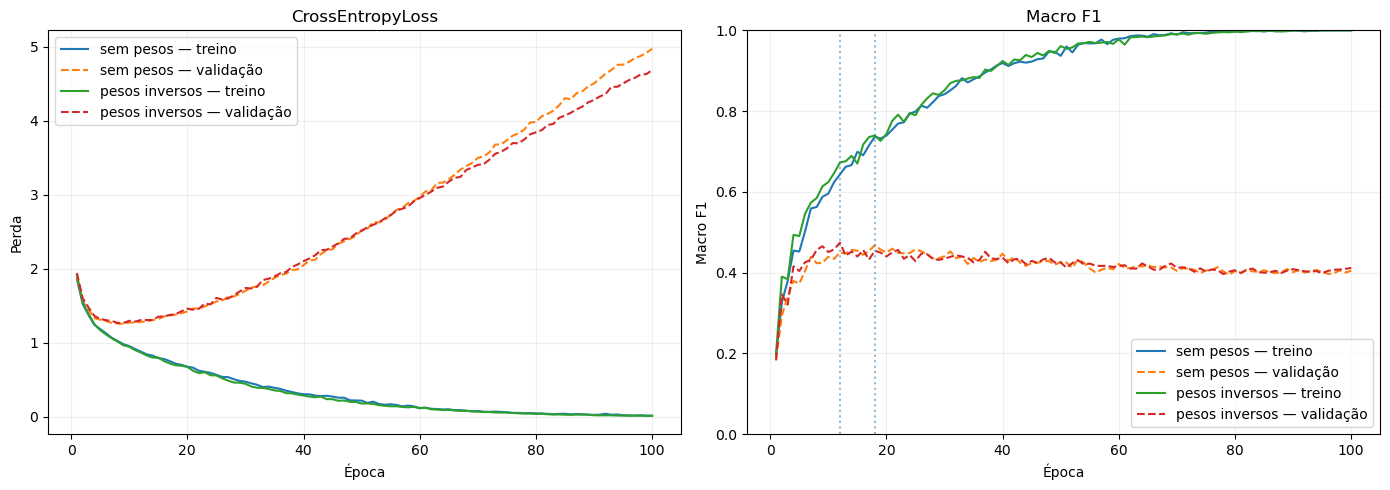

In [3]:
from torch.utils.data import DataLoader, TensorDataset

LOSS_VARIANTS = ['sem pesos', 'pesos inversos']
inner_class_weights = inverse_frequency_weights(y_inner_train_array)
train_dataset = TensorDataset(
    torch.from_numpy(X_inner_train_array),
    torch.from_numpy(y_inner_train_array),
)
histories = {}
selection_rows = []

for variant in LOSS_VARIANTS:
    model = make_mlp(input_size, seed=SEED)
    if variant == 'pesos inversos':
        criterion = torch.nn.CrossEntropyLoss(weight=inner_class_weights)
    else:
        criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE, weight_decay=0
    )
    generator = torch.Generator(device='cpu').manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )
    history = {
        'epoch': [],
        'train_loss': [],
        'validation_loss': [],
        'train_macro_f1': [],
        'validation_macro_f1': [],
    }
    start_time = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for batch_features, batch_targets in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(batch_features)
            loss = criterion(logits, batch_targets)
            loss.backward()
            optimizer.step()
        train_loss, train_macro_f1 = evaluate_loss_f1(
            model, X_inner_train_array, y_inner_train_array, criterion
        )
        validation_loss, validation_macro_f1 = evaluate_loss_f1(
            model, X_inner_val_array, y_inner_val_array, criterion
        )
        history['epoch'].append(epoch)
        history['train_loss'].append(train_loss)
        history['validation_loss'].append(validation_loss)
        history['train_macro_f1'].append(train_macro_f1)
        history['validation_macro_f1'].append(validation_macro_f1)

    training_seconds = time.perf_counter() - start_time
    best_index = int(np.argmax(history['validation_macro_f1']))
    histories[variant] = history
    selection_rows.append({
        'versao': variant,
        'best_epoch': history['epoch'][best_index],
        'train_macro_f1': history['train_macro_f1'][best_index],
        'validation_macro_f1': history['validation_macro_f1'][best_index],
        'train_loss': history['train_loss'][best_index],
        'validation_loss': history['validation_loss'][best_index],
        'training_seconds': training_seconds,
    })

selection_table = pd.DataFrame(selection_rows)
selection_table = selection_table.sort_values(
    'validation_macro_f1', ascending=False, kind='stable'
).reset_index(drop=True)
display(selection_table)
selected_variant = str(selection_table.iloc[0]['versao'])
selected_epoch = int(selection_table.iloc[0]['best_epoch'])
print(f'Versão selecionada pela Macro F1 interna: {selected_variant}')
print(f'Época selecionada: {selected_epoch}')
print(f'Macro F1 interna selecionada: {selection_table.iloc[0]["validation_macro_f1"]:.4f}')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for variant in LOSS_VARIANTS:
    history = histories[variant]
    best_epoch_for_variant = int(selection_table.loc[selection_table['versao'].eq(variant), 'best_epoch'].iloc[0])
    axes[0].plot(history['epoch'], history['train_loss'], label=f'{variant} — treino')
    axes[0].plot(history['epoch'], history['validation_loss'], linestyle='--', label=f'{variant} — validação')
    axes[1].plot(history['epoch'], history['train_macro_f1'], label=f'{variant} — treino')
    axes[1].plot(history['epoch'], history['validation_macro_f1'], linestyle='--', label=f'{variant} — validação')
    axes[1].axvline(best_epoch_for_variant, linestyle=':', alpha=0.5)
axes[0].set(title='CrossEntropyLoss', xlabel='Época', ylabel='Perda')
axes[1].set(title='Macro F1', xlabel='Época', ylabel='Macro F1', ylim=(0, 1))
for axis in axes:
    axis.grid(alpha=0.2)
    axis.legend()
plt.tight_layout()
plt.show()

## Reajuste nos 80% e avaliação única

Criamos uma rede nova, reajustamos o pré-processador nos 80% de treino e treinamos durante a época escolhida. Se a variante ponderada venceu, recalculamos as frequências e os pesos em todos os 80%; caso contrário, mantemos `CrossEntropyLoss()` sem pesos. Em seguida avaliamos uma única vez na validação fixa.

In [4]:
from sklearn.metrics import accuracy_score, classification_report

full_train_preprocessor = build_preprocessor(X_train, normalize_numeric=True)
X_train_array = to_dense_float32(full_train_preprocessor.transform(X_train))
X_val_array = to_dense_float32(full_train_preprocessor.transform(X_val))
y_train_array = y_train.to_numpy(dtype=np.int64)
y_val_array = y_val.to_numpy(dtype=np.int64)

final_model = make_mlp(X_train_array.shape[1], seed=SEED)
if selected_variant == 'pesos inversos':
    final_class_weights = inverse_frequency_weights(y_train_array)
    final_criterion = torch.nn.CrossEntropyLoss(weight=final_class_weights)
    print(f'Pesos finais calculados nos 80%: {final_class_weights.tolist()}')
else:
    final_class_weights = None
    final_criterion = torch.nn.CrossEntropyLoss()
final_optimizer = torch.optim.Adam(
    final_model.parameters(), lr=LEARNING_RATE, weight_decay=0
)
final_dataset = TensorDataset(torch.from_numpy(X_train_array), torch.from_numpy(y_train_array))
final_generator = torch.Generator(device='cpu').manual_seed(SEED)
final_loader = DataLoader(
    final_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=final_generator,
    num_workers=0,
)
for _ in range(selected_epoch):
    final_model.train()
    for batch_features, batch_targets in final_loader:
        final_optimizer.zero_grad(set_to_none=True)
        logits = final_model(batch_features)
        loss = final_criterion(logits, batch_targets)
        loss.backward()
        final_optimizer.step()

final_model.eval()
with torch.no_grad():
    validation_predictions = final_model(torch.from_numpy(X_val_array)).argmax(dim=1).cpu().numpy()
final_macro_f1 = f1_score(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), average='macro', zero_division=0,
)
final_accuracy = accuracy_score(y_val_array, validation_predictions)
final_report = classification_report(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), target_names=[str(i) for i in range(NUM_CLASSES)],
    output_dict=True, zero_division=0,
)
per_class_metrics = pd.DataFrame([
    {
        'AGE_RANGE': class_id,
        'F1': final_report[str(class_id)]['f1-score'],
        'recall': final_report[str(class_id)]['recall'],
        'precision': final_report[str(class_id)]['precision'],
        'support': int(final_report[str(class_id)]['support']),
    }
    for class_id in range(NUM_CLASSES)
])
print(f'Versão final: {selected_variant}; época: {selected_epoch}')
print(f'Macro F1 validação fixa: {final_macro_f1:.4f}')
print(f'Accuracy validação fixa: {final_accuracy:.4f}')
display(per_class_metrics)
print('--- relatório por escalão ---')
print(classification_report(
    y_val_array, validation_predictions,
    labels=list(range(NUM_CLASSES)), target_names=[str(i) for i in range(NUM_CLASSES)],
    zero_division=0,
))

Pesos finais calculados nos 80%: [3.301581382751465, 3.9714674949645996, 1.718064308166504, 1.8147765398025513, 1.5266364812850952, 1.0580357313156128, 0.7977620363235474, 0.7954462766647339, 0.7569923996925354, 0.6757860779762268, 0.645538866519928, 0.6587289571762085, 0.6850781440734863, 0.8329217433929443, 1.0539664030075073, 1.3805100917816162]


Versão final: pesos inversos; época: 12
Macro F1 validação fixa: 0.4073
Accuracy validação fixa: 0.4168


,AGE_RANGE,F1,recall,precision,support
0,0,0.628571,0.536585,0.758621,41
1,1,0.471698,0.735294,0.347222,34
2,2,0.484076,0.475000,0.493506,80
3,3,0.333333,0.333333,0.333333,75
4,4,0.271605,0.244444,0.305556,90
5,5,0.375000,0.465116,0.314136,129
6,6,0.131148,0.093023,0.222222,172
7,7,0.375335,0.404624,0.350000,173
8,8,0.597826,0.607735,0.588235,181
9,9,0.551320,0.463054,0.681159,203


--- relatório por escalão ---
              precision    recall  f1-score   support

           0       0.76      0.54      0.63        41
           1       0.35      0.74      0.47        34
           2       0.49      0.47      0.48        80
           3       0.33      0.33      0.33        75
           4       0.31      0.24      0.27        90
           5       0.31      0.47      0.38       129
           6       0.22      0.09      0.13       172
           7       0.35      0.40      0.38       173
           8       0.59      0.61      0.60       181
           9       0.68      0.46      0.55       203
          10       0.49      0.68      0.57       213
          11       0.45      0.33      0.38       208
          12       0.34      0.49      0.40       200
          13       0.31      0.08      0.13       165
          14       0.31      0.37      0.34       130
          15       0.40      0.61      0.48        99

    accuracy                           0.42      2

## Comparação com o MLP 010

Na validação fixa, o MLP 010 obteve Macro F1 **0,3983** e recall **3/34 (0,0882)** para 18–19 anos (classe 1). A próxima célula compara o F1 e o recall de cada escalão com o 010 para tornar visíveis ganhos e perdas entre classes.

In [5]:
reference_f1 = [
    0.697674, 0.146341, 0.528090, 0.308824,
    0.276596, 0.305882, 0.333333, 0.316547,
    0.570231, 0.541311, 0.563025, 0.482143,
    0.259494, 0.261682, 0.389333, 0.391892,
]
reference_recall = [
    0.731707, 0.088235, 0.587500, 0.280000,
    0.288889, 0.302326, 0.302326, 0.254335,
    0.751381, 0.467980, 0.629108, 0.519231,
    0.205000, 0.254545, 0.561538, 0.292929,
]
class_comparison = per_class_metrics[['AGE_RANGE', 'support', 'F1', 'recall']].copy()
class_comparison['F1_010'] = reference_f1
class_comparison['delta_F1'] = class_comparison['F1'] - class_comparison['F1_010']
class_comparison['recall_010'] = reference_recall
class_comparison['delta_recall'] = class_comparison['recall'] - class_comparison['recall_010']
display(class_comparison)
comparison = pd.DataFrame([
    {'experiencia': '012 - versão selecionada', 'macro_f1_validacao_fixa': final_macro_f1},
    {'experiencia': '010 - MLP referência', 'macro_f1_validacao_fixa': 0.3983},
])
comparison['diferenca_vs_010'] = comparison['macro_f1_validacao_fixa'] - 0.3983
display(comparison)
print(f'Recall 18–19 anos (classe 1): {final_report["1"]["recall"]:.4f} ({int(round(final_report["1"]["recall"] * final_report["1"]["support"]))}/34); referência 010: 3/34')

,AGE_RANGE,support,F1,recall,F1_010,delta_F1,recall_010,delta_recall
0,0,41,0.628571,0.536585,0.697674,-0.069103,0.731707,-0.195122
1,1,34,0.471698,0.735294,0.146341,0.325357,0.088235,0.647059
2,2,80,0.484076,0.475000,0.528090,-0.044014,0.587500,-0.112500
3,3,75,0.333333,0.333333,0.308824,0.024509,0.280000,0.053333
4,4,90,0.271605,0.244444,0.276596,-0.004991,0.288889,-0.044445
5,5,129,0.375000,0.465116,0.305882,0.069118,0.302326,0.162790
6,6,172,0.131148,0.093023,0.333333,-0.202185,0.302326,-0.209303
7,7,173,0.375335,0.404624,0.316547,0.058788,0.254335,0.150289
8,8,181,0.597826,0.607735,0.570231,0.027595,0.751381,-0.143646
9,9,203,0.551320,0.463054,0.541311,0.010009,0.467980,-0.004926


,experiencia,macro_f1_validacao_fixa,diferenca_vs_010
0,012 - versão selecionada,0.40728,0.00898
1,010 - MLP referência,0.39830,0.00000


Recall 18–19 anos (classe 1): 0.7353 (25/34); referência 010: 3/34


## Treino completo e geração da submissão

Após a decisão de submeter, criamos uma rede nova e treinamos por **12 épocas** nas **10.962 linhas rotuladas**. O pré-processador é reajustado em todo o treino e os pesos inversos são recalculados nessas mesmas linhas. O `RowId` vem do exemplo oficial; guardamos apenas `RowId,AGE_RANGE` e recusamos substituir um CSV existente.

In [6]:
from pathlib import Path

if selected_variant != 'pesos inversos' or selected_epoch != 12:
    raise ValueError(
        f'A configuração selecionada mudou: variante={selected_variant!r}, época={selected_epoch}; '
        'não corresponde à submissão aprovada (perda ponderada, 12 épocas).'
    )

submission_path = repo_root / 'submissions' / 'submission_012_mlp_perda_ponderada.csv'
if submission_path.exists():
    raise FileExistsError(f'Não vou substituir uma submissão existente: {submission_path}')

example_candidates = [
    repo_root / 'example_submission_10.csv',
    repo_root / 'notebooks' / 'example_submission_10.csv',
    Path.home() / '.Trash' / 'example_submission_10 21.31.28.csv',
]
example_path = next((candidate for candidate in example_candidates if candidate.is_file()), None)
if example_path is None:
    raise FileNotFoundError(
        'Não encontrei o exemplo oficial com RowId. Coloca example_submission_10.csv '
        'na raiz ou em notebooks/ e volta a executar esta célula.'
    )
example_submission = pd.read_csv(example_path)
if not {'RowId', 'AGE_RANGE'}.issubset(example_submission.columns):
    raise ValueError(f'Colunas inesperadas no exemplo oficial: {example_submission.columns.tolist()}')
row_reference = example_submission[['RowId']].copy()
if row_reference['RowId'].isna().any() or row_reference['RowId'].duplicated().any():
    raise ValueError('RowId do exemplo oficial contém valores ausentes ou duplicados.')

X_full_train = prepared['X_train']
X_kaggle_test = prepared['X_test']
y_full_train = prepared['y_train'].to_numpy(dtype=np.int64)
assert len(X_full_train) == len(y_full_train) == 10962
assert len(X_kaggle_test) == len(row_reference) == 3655

submission_preprocessor = build_preprocessor(X_full_train, normalize_numeric=True)
X_full_train_array = to_dense_float32(submission_preprocessor.transform(X_full_train))
X_kaggle_test_array = to_dense_float32(submission_preprocessor.transform(X_kaggle_test))
full_data_class_weights = inverse_frequency_weights(y_full_train)

submission_model = make_mlp(X_full_train_array.shape[1], seed=SEED)
submission_criterion = torch.nn.CrossEntropyLoss(weight=full_data_class_weights)
submission_optimizer = torch.optim.Adam(
    submission_model.parameters(), lr=LEARNING_RATE, weight_decay=0
)
submission_dataset = TensorDataset(
    torch.from_numpy(X_full_train_array), torch.from_numpy(y_full_train)
)
submission_generator = torch.Generator(device='cpu').manual_seed(SEED)
submission_loader = DataLoader(
    submission_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=submission_generator,
    num_workers=0,
)
submission_start_time = time.perf_counter()
for _ in range(12):
    submission_model.train()
    for batch_features, batch_targets in submission_loader:
        submission_optimizer.zero_grad(set_to_none=True)
        logits = submission_model(batch_features)
        loss = submission_criterion(logits, batch_targets)
        loss.backward()
        submission_optimizer.step()
submission_training_seconds = time.perf_counter() - submission_start_time

submission_model.eval()
with torch.no_grad():
    test_predictions = submission_model(torch.from_numpy(X_kaggle_test_array)).argmax(dim=1).cpu().numpy().astype(np.int64)

submission = row_reference.copy()
submission['AGE_RANGE'] = test_predictions
if list(submission.columns) != ['RowId', 'AGE_RANGE']:
    raise ValueError(f'Formato inesperado da submissão: {submission.columns.tolist()}')
if len(submission) != 3655 or not pd.api.types.is_integer_dtype(submission['AGE_RANGE']):
    raise ValueError('Dimensão ou tipo de AGE_RANGE inválido na submissão.')
if not submission['AGE_RANGE'].between(0, 15).all():
    raise ValueError('AGE_RANGE contém valores fora do intervalo [0, 15].')

submission_path.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(submission_path, index=False)
saved_submission = pd.read_csv(submission_path)
if saved_submission.shape != (3655, 2) or list(saved_submission.columns) != ['RowId', 'AGE_RANGE']:
    raise ValueError('O CSV gravado não respeita o formato esperado.')
if not saved_submission['RowId'].equals(row_reference['RowId']):
    raise ValueError('Os RowId do CSV gravado não correspondem ao exemplo oficial.')
if not pd.api.types.is_integer_dtype(saved_submission['AGE_RANGE']) or not saved_submission['AGE_RANGE'].between(0, 15).all():
    raise ValueError('AGE_RANGE inválido no CSV gravado.')

print(f'Exemplo oficial: {example_path}')
print(f'Submissão guardada: {submission_path}')
print(f'Treino: {len(X_full_train)} linhas, 12 épocas, weight_decay=0')
print(f'Tempo de treino completo: {submission_training_seconds:.2f} s')
print(f'Formato: {saved_submission.shape}; colunas: {saved_submission.columns.tolist()}')
print(f'AGE_RANGE inteiros entre {saved_submission["AGE_RANGE"].min()} e {saved_submission["AGE_RANGE"].max()}')
print(saved_submission['AGE_RANGE'].value_counts().sort_index())

Exemplo oficial: /Users/eduardaferreira/.Trash/example_submission_10 21.31.28.csv
Submissão guardada: /Users/eduardaferreira/daa-kaggle-2026-2027/submissions/submission_012_mlp_perda_ponderada.csv
Treino: 10962 linhas, 12 épocas, weight_decay=0
Tempo de treino completo: 3.43 s
Formato: (3655, 2); colunas: ['RowId', 'AGE_RANGE']
AGE_RANGE inteiros entre 0 e 15
AGE_RANGE
0      68
1      58
2      91
3     158
4     183
5     243
6     151
7     435
8     237
9     167
10    444
11    341
12    532
13    120
14    296
15    131
Name: count, dtype: int64


## Conclusão e Decisão 
- Data: 10/11
- Pontuação Kaggle:0.43
- Conclusão: A ponderação aumentou o recall dos 18–19 anos de 3/34 para 25/34, mas reduziu o recall noutros escalões, incluindo 40–44 e 75–79 anos.
- Melhorias: Comparar arquiteturas, começando por 64, 64 → 32 e 128 → 64, com a mesma divisão interna e a mesma perda ponderada.

- Na validação fixa, a perda ponderada subiu a Macro F1 de 0,3983 para 0,4073 (+0,0090), apesar da ligeira descida da accuracy de 41,95% para 41,68%. Como a competição usa Macro F1, a melhoria é relevante.